# Data-Driven Parcel Locker Placement
### Geographical demand analysis, weighted K-Means and facility-location optimization

This project studies where an e-commerce company could place **five parcel pickup lockers in São Paulo**. Historical Olist orders provide an estimate of demand. Weighted K-Means generates possible locations, and a p-median model selects sites that minimize the average order-weighted distance to a locker.

The analysis asks four questions:

1. How is order demand distributed across the city?
2. Does optimization improve on a clustering-based placement when evaluated on later orders?
3. How does service distance change with the number of lockers?
4. Does excluding isolated ZIP points from candidate generation change service for the full demand cohort?

The locations are hypothetical: a ZIP-prefix coordinate does not establish that a property is available for installation. Distances are straight-line kilometres, rather than walking or road distances. One historical order is treated as one unit of potential parcel demand.

## 1. Setup and data sources

The notebook uses three tables from the [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): customers, orders and geolocation.


In [ ]:
# Uncomment once if the packages are not installed in the notebook environment.
# %pip install numpy pandas matplotlib scikit-learn scipy pyproj jinja2

from pathlib import Path
from urllib.request import urlopen
from time import perf_counter
import hashlib
import platform
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import pyproj
from pyproj import Transformer
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.optimize import Bounds, LinearConstraint, milp, linear_sum_assignment
from scipy.sparse import coo_matrix
from IPython.display import display, Markdown

SEED = 42
DATA_DIR = Path('data/olist')
OUTPUT_DIR = Path('outputs/parcel_lockers')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LOCKER_COUNT = 5
CANDIDATE_COUNTS = [15, 20, 30]
LOCKER_COUNTS = [3, 5, 7, 10]
WCSS_K_VALUES = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 40]
ISOLATION_NEIGHBORS = 5
ISOLATION_IQR_MULTIPLIER = 1.5
RANDOM_RUNS = 200
SOLVER_SECONDS = 90
RELATIVE_GAP = 0.001

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'semibold', 'axes.grid': False,
})
COLORS = {'K-Means': '#597b96', 'p-median': '#c36b3c', 'Random': '#929a9e'}
pd.set_option('display.max_columns', 20)

def show_table(frame, decimals=3):
    display(frame.style.format(precision=decimals, na_rep='—').hide(axis='index'))

def finish_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

versions = pd.DataFrame({
    'Package': ['Python', 'numpy', 'pandas', 'scikit-learn', 'scipy', 'pyproj'],
    'Version': [platform.python_version(), np.__version__, pd.__version__,
                sklearn.__version__, scipy.__version__, pyproj.__version__],
})
show_table(versions)

Package,Version
Python,3.13.16
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
scipy,1.16.3
pyproj,3.8.0


In [ ]:
DATA_REVISION = 'd9e49802f3e92d09ee94ab9ccc5e457f207a8959'
DATA_BASE = f'https://raw.githubusercontent.com/olist/work-at-olist-data/{DATA_REVISION}/datasets/'
FILE_SPECS = {
    'customers': {
        'file': 'olist_customers_dataset.csv',
        'sha256': 'c26c17f59f3027a6a0dbeb8f1fa373c38f3323ecc84f225a8f4820e5bb288df8',
        'columns': ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
                    'customer_city', 'customer_state'],
    },
    'orders': {
        'file': 'olist_orders_dataset.csv',
        'sha256': '8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c91cec19ae3345ef9ecf',
        'columns': ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
                    'order_delivered_customer_date'],
    },
    'geolocation': {
        'file': 'olist_geolocation_dataset.csv',
        'sha256': 'b514f6fc991b9566aeba02aa5d67e2c3630f034b60a0e05aa0d082a3b66d88d6',
        'columns': ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng',
                    'geolocation_state'],
    },
}

def file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def load_source(spec):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    path = DATA_DIR / spec['file']
    if not path.exists() or path.stat().st_size == 0:
        partial = path.with_suffix('.csv.part')
        print('Downloading', spec['file'])
        try:
            with urlopen(DATA_BASE + spec['file'], timeout=90) as response:
                with partial.open('wb') as handle:
                    while chunk := response.read(1024 * 1024):
                        handle.write(chunk)
            if partial.stat().st_size == 0 or file_hash(partial) != spec['sha256']:
                raise ValueError('Downloaded file is empty, incomplete or differs from the pinned source.')
            partial.replace(path)
        except Exception as error:
            partial.unlink(missing_ok=True)
            raise RuntimeError(f'Could not obtain {spec["file"]}. Check the source link and internet connection.') from error
    if file_hash(path) != spec['sha256']:
        raise ValueError(f'{path} differs from the pinned CSV. Move it aside and rerun to download the reference file.')
    header = pd.read_csv(path, nrows=0)
    missing = set(spec['columns']) - set(header.columns)
    if missing:
        raise ValueError(f'{path.name}: missing columns {sorted(missing)}')
    zip_columns = {name: 'string' for name in header.columns if 'zip_code_prefix' in name}
    return pd.read_csv(path, dtype=zip_columns)

tables = {name: load_source(spec) for name, spec in FILE_SPECS.items()}
customers_raw = tables['customers']
orders_raw = tables['orders']
geo_raw = tables['geolocation']

source_summary = pd.DataFrame([
    {'Table': name, 'Rows': len(tables[name]), 'Columns': tables[name].shape[1],
     'File size (MB)': (DATA_DIR / spec['file']).stat().st_size / 1e6,
     'SHA-256 prefix': spec['sha256'][:12]}
    for name, spec in FILE_SPECS.items()
])
show_table(source_summary, 2)

Table,Rows,Columns,File size (MB),SHA-256 prefix
customers,99441,5,8.56,c26c17f59f30
orders,99441,8,17.65,8df58ef3d2d7
geolocation,1000163,5,61.27,b514f6fc991b


## 2. Data quality and preprocessing

`customer_id` links an order to its customer record. It is not a permanent person identifier; repeat buyers are identified by `customer_unique_id`. Demand is counted using unique **orders**, not rows from the geolocation table or counts of unique buyers.

Geolocation has several coordinate observations for a ZIP prefix. Repeated prefixes are expected. Exact duplicate geolocation records are removed, then median latitude and longitude provide one representative point per prefix. Customer and order IDs are checked before joining so that duplicates cannot multiply order demand.

These preprocessing checks handle missing, duplicated or implausible records. They are separate from the geographic isolation check below. A valid point far from other points can represent genuine demand and is not automatically a data error.

In [ ]:
quality_rows = []
key_names = {'customers': 'customer_id', 'orders': 'order_id',
             'geolocation': 'geolocation_zip_code_prefix'}
for name, frame in tables.items():
    quality_rows.append({
        'Table': name, 'Exact duplicate rows': int(frame.duplicated().sum()),
        'Repeated key rows': int(frame[key_names[name]].duplicated().sum()),
        'Rows with any missing field': int(frame.isna().any(axis=1).sum()),
    })
show_table(pd.DataFrame(quality_rows), 0)

missing_values = pd.DataFrame([
    {'Table': name, 'Column': column, 'Missing rows': int(frame[column].isna().sum())}
    for name, frame in tables.items()
    for column in FILE_SPECS[name]['columns']
])
show_table(missing_values, 0)

customers = customers_raw.drop_duplicates().copy()
orders = orders_raw.drop_duplicates().copy()
if customers['customer_id'].isna().any() or customers['customer_id'].duplicated().any():
    raise ValueError('Customer IDs must be nonmissing and unique before the join.')
if orders['order_id'].isna().any() or orders['order_id'].duplicated().any():
    raise ValueError('Order IDs must be nonmissing and unique before the join.')

def normalize_city(value):
    if pd.isna(value):
        return ''
    text = unicodedata.normalize('NFKD', str(value))
    return text.encode('ascii', 'ignore').decode('ascii').strip().lower()

def clean_prefix(series):
    cleaned = series.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
    return cleaned.where(cleaned.str.fullmatch(r'\d{1,5}', na=False)).str.zfill(5)

customers['zip_prefix'] = clean_prefix(customers['customer_zip_code_prefix'])
customers['city_clean'] = customers['customer_city'].map(normalize_city)
orders['purchase_date'] = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')
orders['delivered_date'] = pd.to_datetime(orders['order_delivered_customer_date'], errors='coerce')
geo = geo_raw.drop_duplicates().copy()
geo['zip_prefix'] = clean_prefix(geo['geolocation_zip_code_prefix'])
geo['lat'] = pd.to_numeric(geo['geolocation_lat'], errors='coerce')
geo['lon'] = pd.to_numeric(geo['geolocation_lng'], errors='coerce')

# Broad regional bounds remove implausible geocodes; city membership comes from customers.
geo_valid = geo.loc[
    geo['zip_prefix'].notna() & geo['geolocation_state'].eq('SP') &
    geo['lat'].between(-24.25, -22.70) & geo['lon'].between(-47.70, -45.70)
].copy()
geo_reference = geo_valid.groupby('zip_prefix', as_index=False).agg(
    lat=('lat', 'median'), lon=('lon', 'median'), geo_observations=('lat', 'size')
)

joined_orders = orders.merge(
    customers[['customer_id', 'customer_unique_id', 'zip_prefix', 'city_clean', 'customer_state']],
    on='customer_id', how='left', validate='many_to_one', indicator='customer_match'
)
city_orders = joined_orders.loc[
    joined_orders['city_clean'].eq('sao paulo') & joined_orders['customer_state'].eq('SP')
].copy()
delivered_orders = city_orders.loc[city_orders['order_status'].eq('delivered')].copy()
dated_orders = delivered_orders.loc[delivered_orders['purchase_date'].notna()].copy()
located_orders = dated_orders.merge(
    geo_reference, on='zip_prefix', how='left', validate='many_to_one', indicator='geo_match'
)
order_areas = located_orders.loc[located_orders['geo_match'].eq('both')].copy()
order_areas = order_areas.sort_values(['purchase_date', 'order_id']).reset_index(drop=True)

filter_summary = pd.DataFrame({
    'Stage': ['Unique source orders', 'Customer record matched', 'São Paulo city',
              'Delivered city orders', 'Valid purchase date', 'Valid representative coordinate'],
    'Orders retained': [len(orders), joined_orders['customer_match'].eq('both').sum(),
                        len(city_orders), len(delivered_orders), len(dated_orders), len(order_areas)],
})
filter_summary['Removed since previous stage'] = -filter_summary['Orders retained'].diff().fillna(0).astype(int)
show_table(filter_summary, 0)
print(f'Geolocation match rate among dated delivered city orders: {len(order_areas) / len(dated_orders):.2%}')
print('Geolocation rows: raw / deduplicated / eligible regional:', len(geo_raw), len(geo), len(geo_valid))
assert order_areas['order_id'].is_unique and len(order_areas) > 1000

Table,Exact duplicate rows,Repeated key rows,Rows with any missing field
customers,0,0,0
orders,0,0,2980
geolocation,261831,981148,0


Table,Column,Missing rows
customers,customer_id,0
customers,customer_unique_id,0
customers,customer_zip_code_prefix,0
customers,customer_city,0
customers,customer_state,0
orders,order_id,0
orders,customer_id,0
orders,order_status,0
orders,order_purchase_timestamp,0
orders,order_delivered_customer_date,2965


Stage,Orders retained,Removed since previous stage
Unique source orders,99441,0
Customer record matched,99441,0
São Paulo city,15540,83901
Delivered city orders,15045,495
Valid purchase date,15045,0
Valid representative coordinate,15043,2


Geolocation match rate among dated delivered city orders: 99.99%
Geolocation rows: raw / deduplicated / eligible regional: 1000163 738332 203598


## 3. Time split and study coverage

The earliest approximately 60% of orders form the training period, the next approximately 20% form validation, and the latest approximately 20% form the test period. Boundaries are moved to whole days so that orders from the same day do not straddle periods.

Training and validation decide the candidate-site count. The final placement is then refitted on the combined development period. Test orders are used only for the final comparison and the predeclared locker-count scenarios. All eligible ZIP areas are retained; there is no top-70-area filter.

In [ ]:
validation_start = order_areas['purchase_date'].iloc[int(0.60 * len(order_areas))].normalize()
test_start = order_areas['purchase_date'].iloc[int(0.80 * len(order_areas))].normalize()
train_orders = order_areas.loc[order_areas['purchase_date'] < validation_start].copy()
validation_orders = order_areas.loc[
    order_areas['purchase_date'].ge(validation_start) & order_areas['purchase_date'].lt(test_start)
].copy()
test_orders = order_areas.loc[order_areas['purchase_date'] >= test_start].copy()
development_orders = pd.concat([train_orders, validation_orders], ignore_index=True)

def demand_table(order_frame):
    return order_frame.groupby('zip_prefix', as_index=False).agg(
        lat=('lat', 'first'), lon=('lon', 'first'), orders=('order_id', 'nunique')
    ).sort_values('zip_prefix').reset_index(drop=True)

train_demand = demand_table(train_orders)
validation_demand = demand_table(validation_orders)
development_demand = demand_table(development_orders)
test_demand = demand_table(test_orders)
all_demand = demand_table(order_areas)

split_summary = pd.DataFrame([
    {'Period': name, 'Orders': len(frame), 'ZIP areas': frame['zip_prefix'].nunique(),
     'First purchase': frame['purchase_date'].min().strftime('%Y-%m-%d'),
     'Last purchase': frame['purchase_date'].max().strftime('%Y-%m-%d')}
    for name, frame in [('Training', train_orders), ('Validation', validation_orders), ('Test', test_orders)]
])
show_table(split_summary, 0)

train_ranked = train_demand.sort_values('orders', ascending=False)
top70_prefixes = set(train_ranked.head(70)['zip_prefix'])
coverage_comparison = pd.DataFrame([
    {'Study scope': 'Top 70 training ZIP areas',
     'Training orders covered (%)': 100 * train_orders['zip_prefix'].isin(top70_prefixes).mean(),
     'Test orders covered (%)': 100 * test_orders['zip_prefix'].isin(top70_prefixes).mean()},
    {'Study scope': 'All eligible city ZIP areas',
     'Training orders covered (%)': 100.0, 'Test orders covered (%)': 100.0},
])
show_table(coverage_comparison, 2)
new_test_orders = (~test_orders['zip_prefix'].isin(development_demand['zip_prefix'])).sum()
display(Markdown(
    f'The final evaluation includes **{len(test_orders):,} orders** across **{len(test_demand):,} ZIP areas**. '
    f'Of these, **{new_test_orders:,} orders ({new_test_orders / len(test_orders):.1%})** belong to prefixes '
    'not seen in development. They are still evaluated against the selected sites because their coordinates are available.'
))
assert train_orders['purchase_date'].max() < validation_orders['purchase_date'].min()
assert validation_orders['purchase_date'].max() < test_orders['purchase_date'].min()
assert len(train_orders) + len(validation_orders) + len(test_orders) == len(order_areas)

Period,Orders,ZIP areas,First purchase,Last purchase
Training,9006,2540,2016-10-03,2018-03-21
Validation,2993,1606,2018-03-22,2018-06-10
Test,3044,1650,2018-06-11,2018-08-29


Study scope,Training orders covered (%),Test orders covered (%)
Top 70 training ZIP areas,11.06,8.61
All eligible city ZIP areas,100.00,100.00


The final evaluation includes **3,044 orders** across **1,650 ZIP areas**. Of these, **156 orders (5.1%)** belong to prefixes not seen in development. They are still evaluated against the selected sites because their coordinates are available.

In [ ]:
if 'order_areas' not in globals():
    print("Loading and preprocessing tables to reconstruct 'order_areas'...")
    tables = {name: load_source(spec) for name, spec in FILE_SPECS.items()}
    customers_raw, orders_raw, geo_raw = tables['customers'], tables['orders'], tables['geolocation']

    customers = customers_raw.drop_duplicates().copy()
    orders = orders_raw.drop_duplicates().copy()
    customers['zip_prefix'] = clean_prefix(customers['customer_zip_code_prefix'])
    customers['city_clean'] = customers['customer_city'].map(normalize_city)
    orders['purchase_date'] = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')
    orders['delivered_date'] = pd.to_datetime(orders['order_delivered_customer_date'], errors='coerce')

    geo = geo_raw.drop_duplicates().copy()
    geo['zip_prefix'] = clean_prefix(geo['geolocation_zip_code_prefix'])
    geo['lat'] = pd.to_numeric(geo['geolocation_lat'], errors='coerce')
    geo['lon'] = pd.to_numeric(geo['geolocation_lng'], errors='coerce')

    geo_valid = geo.loc[
        geo['zip_prefix'].notna() & geo['geolocation_state'].eq('SP') &
        geo['lat'].between(-24.25, -22.70) & geo['lon'].between(-47.70, -45.70)
    ].copy()
    geo_reference = geo_valid.groupby('zip_prefix', as_index=False).agg(
        lat=('lat', 'median'), lon=('lon', 'median'), geo_observations=('lat', 'size')
    )

    joined_orders = orders.merge(
        customers[['customer_id', 'customer_unique_id', 'zip_prefix', 'city_clean', 'customer_state']],
        on='customer_id', how='left', validate='many_to_one'
    )
    city_orders = joined_orders.loc[
        joined_orders['city_clean'].eq('sao paulo') & joined_orders['customer_state'].eq('SP')
    ].copy()
    delivered_orders = city_orders.loc[city_orders['order_status'].eq('delivered')].copy()
    dated_orders = delivered_orders.loc[delivered_orders['purchase_date'].notna()].copy()
    located_orders = dated_orders.merge(
        geo_reference, on='zip_prefix', how='left', validate='many_to_one', indicator='geo_match'
    )
    order_areas = located_orders.loc[located_orders['geo_match'].eq('both')].copy()
    order_areas = order_areas.sort_values(['purchase_date', 'order_id']).reset_index(drop=True)

unique_customers = order_areas['customer_unique_id'].nunique()
unique_locations = order_areas['zip_prefix'].nunique()

print(f"Unique Customers: {unique_customers:,}")
print(f"Unique ZIP Prefix Locations: {unique_locations:,}")

Unique Customers: 14,526
Unique ZIP Prefix Locations: 2,824


## 4. Exploratory demand analysis

Order volume shows whether a single historical snapshot is representative of the full period. The concentration curve shows how much demand a small selection of ZIP areas would retain. Geographic plots use development-period demand so that later orders do not determine candidate locations.

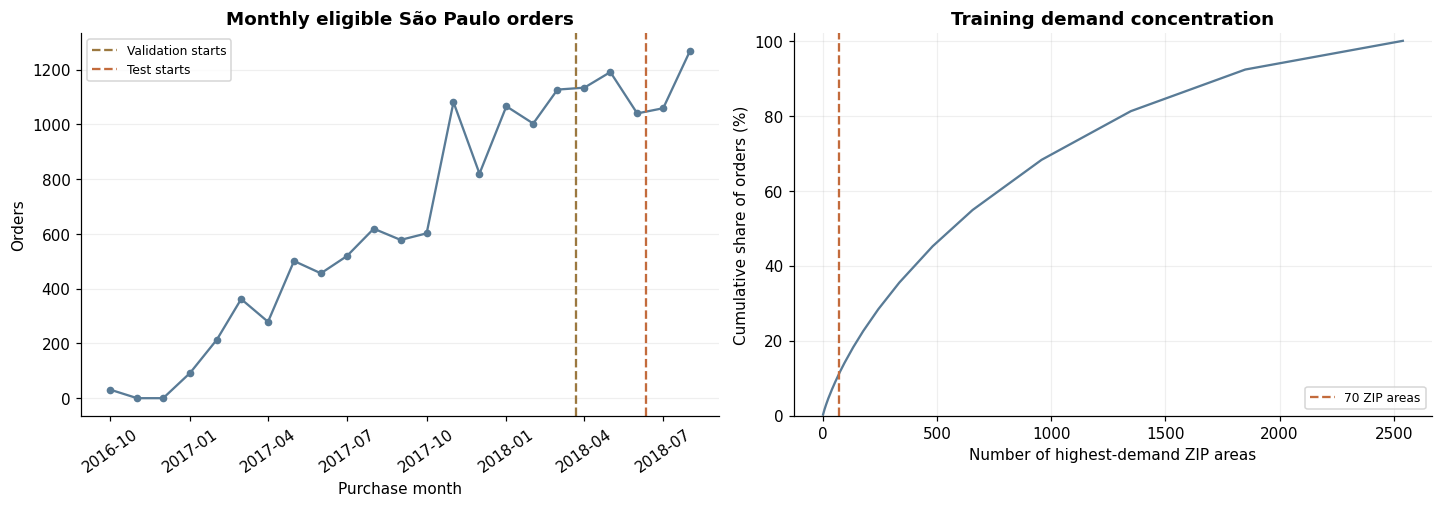

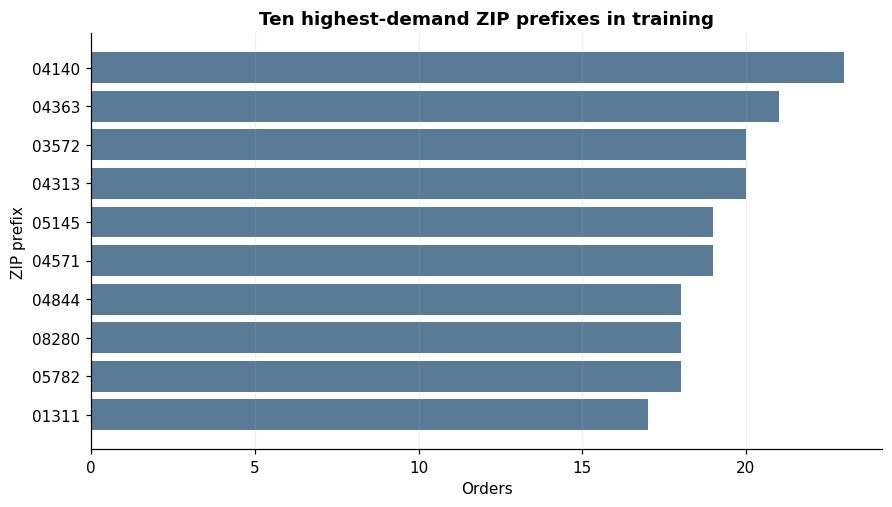

The highest-demand **70 prefixes account for 11.1% of training orders**. It takes **568 prefixes** to cover half of training demand. This is why the optimization retains the full eligible city coverage.

In [ ]:
monthly_orders = order_areas.set_index('purchase_date').resample('MS')['order_id'].nunique()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].plot(monthly_orders.index, monthly_orders.values, color=COLORS['K-Means'], marker='o', markersize=4)
axes[0].axvline(validation_start, color='#9b783f', linestyle='--', label='Validation starts')
axes[0].axvline(test_start, color=COLORS['p-median'], linestyle='--', label='Test starts')
axes[0].set(title='Monthly eligible São Paulo orders', xlabel='Purchase month', ylabel='Orders')
axes[0].tick_params(axis='x', rotation=35)
axes[0].legend(fontsize=8)
axes[0].grid(axis='y', alpha=0.2)

ranked_demand = train_demand.sort_values('orders', ascending=False).reset_index(drop=True)
cumulative_share = ranked_demand['orders'].cumsum() / ranked_demand['orders'].sum()
axes[1].plot(np.arange(1, len(ranked_demand) + 1), 100 * cumulative_share, color=COLORS['K-Means'])
axes[1].axvline(70, linestyle='--', color=COLORS['p-median'], label='70 ZIP areas')
axes[1].set(title='Training demand concentration', xlabel='Number of highest-demand ZIP areas',
            ylabel='Cumulative share of orders (%)', ylim=(0, 102))
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)
finish_figure(fig, '01_time_and_concentration.png')

top10 = ranked_demand.head(10).sort_values('orders')
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.barh(top10['zip_prefix'], top10['orders'], color=COLORS['K-Means'])
ax.set(title='Ten highest-demand ZIP prefixes in training', xlabel='Orders', ylabel='ZIP prefix')
ax.grid(axis='x', alpha=0.2)
finish_figure(fig, '02_top_zip_areas.png')

areas_for_half = int(np.searchsorted(cumulative_share.to_numpy(), 0.5) + 1)
display(Markdown(
    f'The highest-demand **70 prefixes account for {100 * cumulative_share.iloc[69]:.1f}% of training orders**. '
    f'It takes **{areas_for_half:,} prefixes** to cover half of training demand. '
    'This is why the optimization retains the full eligible city coverage.'
))

## 5. Geographic coordinates and geolocation uncertainty

K-Means requires Euclidean coordinates. Latitude and longitude are converted to **WGS 84 / UTM zone 23S (EPSG:32723)**, which is appropriate for São Paulo. Clustering and plots use projected kilometres; placement evaluation uses Haversine great-circle distances.

For each eligible ZIP prefix, the spread of its source coordinates is measured around the median point. A large spread means that the representative coordinate should be interpreted cautiously. These observations are geocodes, not verified individual customer addresses.

zip_prefix,observations,median_offset_km,p90_offset_km,maximum_offset_km
04893,19,1.282,49.450,53.873
04895,66,0.656,34.801,49.349
01430,8,1.062,34.044,34.127
01431,10,0.889,34.013,34.110
04961,29,0.333,31.492,32.247
02169,36,1.933,30.232,38.390
05272,21,0.213,28.398,28.411
08383,3,2.852,27.946,34.220
04472,19,0.126,27.006,31.579
04891,24,0.643,25.821,50.158


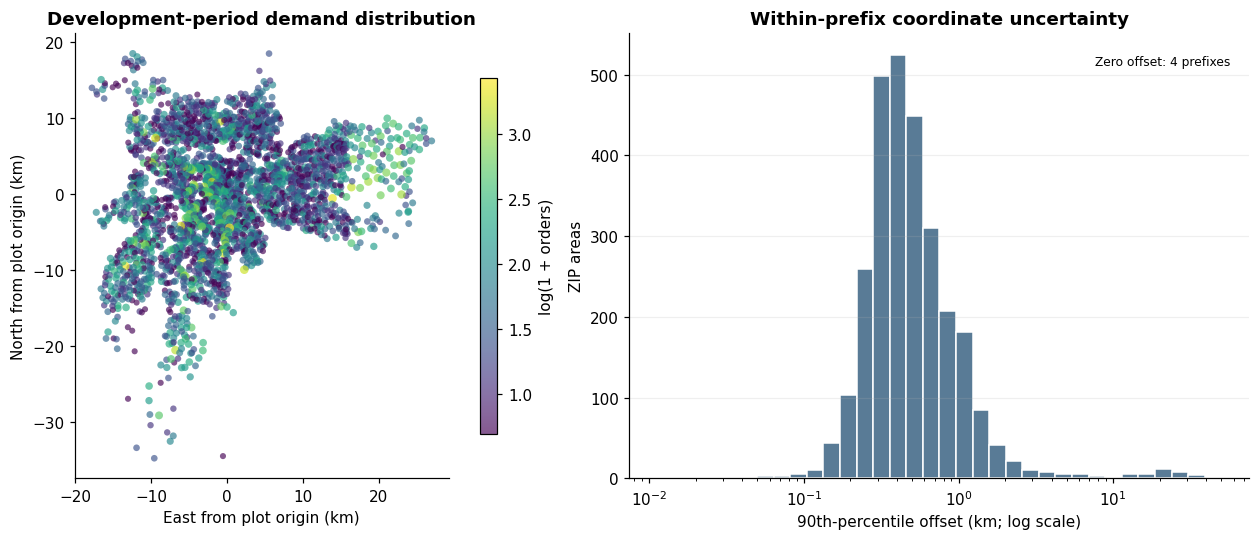

For **90% of studied ZIP prefixes**, the within-prefix 90th-percentile coordinate offset is no more than **1.12 km**. The largest-spread prefixes remain visible in the table above; their uncertainty is not removed simply to improve the placement results.

In [ ]:
projector = Transformer.from_crs('EPSG:4326', 'EPSG:32723', always_xy=True)

def projected_km(frame):
    east, north = projector.transform(frame['lon'].to_numpy(), frame['lat'].to_numpy())
    return np.column_stack([east, north]) / 1000.0

def haversine_km(first, second):
    # Input columns are latitude and longitude; output is a pairwise distance matrix.
    a = np.radians(np.asarray(first, dtype=float))
    b = np.radians(np.asarray(second, dtype=float))
    delta_lat = a[:, None, 0] - b[None, :, 0]
    delta_lon = a[:, None, 1] - b[None, :, 1]
    h = (np.sin(delta_lat / 2) ** 2 + np.cos(a[:, None, 0]) *
         np.cos(b[None, :, 0]) * np.sin(delta_lon / 2) ** 2)
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

geo_city = geo_valid.loc[geo_valid['zip_prefix'].isin(all_demand['zip_prefix'])].merge(
    geo_reference[['zip_prefix', 'lat', 'lon']], on='zip_prefix', validate='many_to_one',
    suffixes=('', '_median')
)
observed_xy = projected_km(geo_city)
median_xy = projected_km(geo_city.rename(columns={'lat': 'source_lat', 'lon': 'source_lon',
                                                'lat_median': 'lat', 'lon_median': 'lon'}))
geo_city['offset_km'] = np.linalg.norm(observed_xy - median_xy, axis=1)
coordinate_spread = geo_city.groupby('zip_prefix', as_index=False).agg(
    observations=('offset_km', 'size'), median_offset_km=('offset_km', 'median'),
    p90_offset_km=('offset_km', lambda values: values.quantile(0.90)),
    maximum_offset_km=('offset_km', 'max')
)
show_table(coordinate_spread.sort_values('p90_offset_km', ascending=False).head(10), 3)

development_xy = projected_km(development_demand)
plot_origin = development_xy.mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
points = axes[0].scatter(*(development_xy - plot_origin).T,
                         s=12 + 4 * np.sqrt(development_demand['orders']),
                         c=np.log1p(development_demand['orders']), cmap='viridis', alpha=0.65,
                         linewidths=0)
axes[0].set(title='Development-period demand distribution', xlabel='East from plot origin (km)',
            ylabel='North from plot origin (km)')
axes[0].set_aspect('equal', adjustable='box')
fig.colorbar(points, ax=axes[0], label='log(1 + orders)', shrink=0.8)
offsets = coordinate_spread['p90_offset_km'].to_numpy()
positive_offsets = offsets[offsets > 0]
bins = np.geomspace(positive_offsets.min(), positive_offsets.max() * 1.01, 35)
axes[1].hist(positive_offsets, bins=bins, color=COLORS['K-Means'], edgecolor='white')
axes[1].set_xscale('log')
axes[1].text(0.97, 0.95, f'Zero offset: {np.sum(offsets == 0)} prefixes',
             transform=axes[1].transAxes, ha='right', va='top', fontsize=8)
axes[1].set(title='Within-prefix coordinate uncertainty', xlabel='90th-percentile offset (km; log scale)',
            ylabel='ZIP areas')
axes[1].grid(axis='y', alpha=0.2)
finish_figure(fig, '03_demand_and_coordinate_spread.png')

spread_p90 = coordinate_spread['p90_offset_km'].quantile(0.9)
display(Markdown(
    f'For **90% of studied ZIP prefixes**, the within-prefix 90th-percentile coordinate offset is '
    f'no more than **{spread_p90:.2f} km**. The largest-spread prefixes remain visible in the table above; '
    'their uncertainty is not removed simply to improve the placement results.'
))

## 6. Weighted K-Means and distinct candidate sites

Each ZIP point receives a weight equal to its number of development orders. K-Means therefore represents busy areas more strongly without expanding every order into a repeated coordinate row.

A cluster centre may fall between buildings. Centres are mapped to distinct ZIP-prefix representative coordinates using a minimum-total-distance matching. This avoids duplicate sites and avoids making the snapping result depend on the order in which centres are processed. These representative coordinates are still hypothetical installation sites.

For the clustering baseline, five weighted centres are mapped to the same candidate pool used by optimization. K-Means minimizes **squared Euclidean distance**, whereas p-median minimizes **order-weighted distance**. Their objectives differ, which is one reason to compare them using a common held-out metric.

Two different counts are used:

| Symbol | Meaning | How it is set |
|---|---|---|
| $k$ in candidate generation | Number of weighted demand clusters used to propose candidate sites | Compare 15, 20 and 30 using validation service distance. |
| $p$ in p-median | Number of lockers opened from the candidate pool | Five in the main planning scenario; 3, 7 and 10 are separate scenarios. |
| $k=p$ in the baseline | Number of centres used to propose the baseline's $p$ lockers | Equal to the locker count so that the baseline opens the same number of sites. |

The p-median model does not require a particular K-Means cluster count. Clustering generates the choices; optimization chooses among them. Five lockers is an experimental planning budget, not a value estimated from an elbow plot.


In [ ]:
def distinct_nearest_sites(centers_xy, available_xy):
    distance = np.linalg.norm(centers_xy[:, None, :] - available_xy[None, :, :], axis=2)
    center_rows, point_rows = linear_sum_assignment(distance)
    if len(center_rows) != len(centers_xy):
        raise ValueError('There are fewer distinct locations than requested centres.')
    selected = np.empty(len(centers_xy), dtype=int)
    selected[center_rows] = point_rows
    return selected

def make_candidates(demand, count):
    unique_coordinates = demand.drop_duplicates(['lat', 'lon']).reset_index(drop=True)
    if count > len(unique_coordinates):
        raise ValueError('Too many candidates for the observed distinct coordinates.')
    model = KMeans(n_clusters=count, n_init=20, random_state=SEED)
    model.fit(projected_km(demand), sample_weight=demand['orders'].to_numpy())
    rows = distinct_nearest_sites(model.cluster_centers_, projected_km(unique_coordinates))
    sites = unique_coordinates.iloc[rows][['zip_prefix', 'lat', 'lon']].reset_index(drop=True)
    sites['site_id'] = [f'S{number:02d}' for number in range(1, count + 1)]
    return sites, model

def kmeans_placement(demand, sites, count):
    model = KMeans(n_clusters=count, n_init=20, random_state=SEED)
    model.fit(projected_km(demand), sample_weight=demand['orders'].to_numpy())
    return distinct_nearest_sites(model.cluster_centers_, projected_km(sites)).tolist()

def distance_matrix(demand, sites):
    return haversine_km(demand[['lat', 'lon']].to_numpy(), sites[['lat', 'lon']].to_numpy())

## 6.1 Demand-weighted WCSS as a clustering diagnostic

For ZIP point $i$, let $z_i$ be its projected coordinate in kilometres, $w_i$ its training order count, and $c(i)$ its assigned cluster. The demand-weighted within-cluster sum of squares is

$$\mathrm{WCSS}_w(k)=\sum_i w_i\left\|z_i-\mu_{c(i)}\right\|_2^2,$$

with weighted centroid

$$\mu_c=\frac{\sum_{i:c(i)=c}w_i z_i}{\sum_{i:c(i)=c}w_i}.$$

This is equivalent to repeating each ZIP coordinate once per order. Its units are order-count times squared kilometres. Dividing by $\sum_iw_i$ gives mean squared distance in $\mathrm{km}^2$; taking its square root gives the root mean squared distance in kilometres.

Every value of $k$ uses the **same full training ZIP points and weights**. The explicit weighted calculation is checked against scikit-learn's fitted inertia. Smaller WCSS means more compact clusters, but the curve alone does not choose the best locker network: it concerns squared projected distance before snapping centres to candidate sites. Candidate counts are selected below using validation p-median service distance. The locker budget $p$ remains a separate input.

Clusters k,Weighted WCSS (order km²),Mean squared distance (km²),RMS distance (km)
1,1344260.731,149.263,12.217
2,745723.953,82.803,9.100
3,459792.079,51.054,7.145
5,291192.668,32.333,5.686
7,204227.558,22.677,4.762
10,136433.066,15.149,3.892
15,84042.503,9.332,3.055
20,63204.518,7.018,2.649
25,49801.958,5.530,2.352
30,41066.866,4.560,2.135


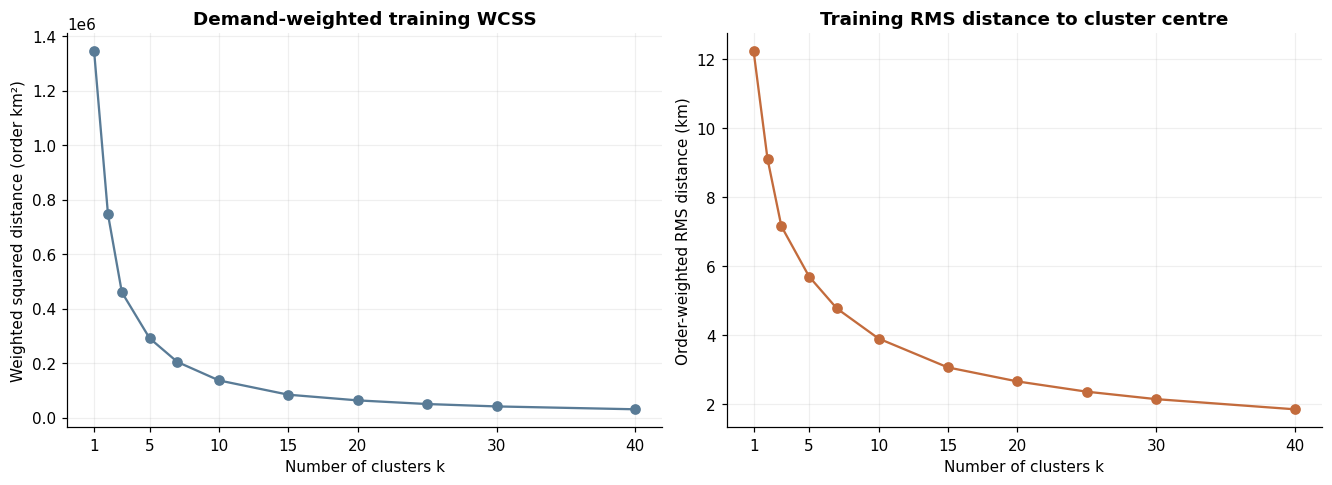

Weighted WCSS agrees with fitted inertia for every tested k.


In [ ]:
training_xy = projected_km(train_demand)
training_weights = train_demand['orders'].to_numpy(dtype=float)
wcss_rows = []
for count in WCSS_K_VALUES:
    model = KMeans(n_clusters=count, n_init=20, random_state=SEED, tol=1e-6)
    model.fit(training_xy, sample_weight=training_weights)
    squared_distance = np.sum((training_xy - model.cluster_centers_[model.labels_]) ** 2, axis=1)
    explicit_wcss = float(np.dot(training_weights, squared_distance))
    assert np.isclose(explicit_wcss, model.inertia_, rtol=1e-8, atol=1e-5)
    wcss_rows.append({
        'Clusters k': count, 'Weighted WCSS (order km²)': explicit_wcss,
        'Mean squared distance (km²)': explicit_wcss / training_weights.sum(),
        'RMS distance (km)': np.sqrt(explicit_wcss / training_weights.sum()),
        'Training ZIP areas': len(train_demand), 'Training orders': int(training_weights.sum()),
    })
weighted_wcss = pd.DataFrame(wcss_rows)
show_table(weighted_wcss[['Clusters k', 'Weighted WCSS (order km²)',
                          'Mean squared distance (km²)', 'RMS distance (km)']], 3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
axes[0].plot(weighted_wcss['Clusters k'], weighted_wcss['Weighted WCSS (order km²)'],
             marker='o', color=COLORS['K-Means'])
axes[0].set(title='Demand-weighted training WCSS', xlabel='Number of clusters k',
            ylabel='Weighted squared distance (order km²)')
axes[1].plot(weighted_wcss['Clusters k'], weighted_wcss['RMS distance (km)'],
             marker='o', color=COLORS['p-median'])
axes[1].set(title='Training RMS distance to cluster centre', xlabel='Number of clusters k',
            ylabel='Order-weighted RMS distance (km)')
for ax in axes:
    ax.set_xticks([1, 5, 10, 15, 20, 30, 40])
    ax.grid(alpha=0.2)
finish_figure(fig, '09_weighted_wcss.png')
print('Weighted WCSS agrees with fitted inertia for every tested k.')

## 6.2 Flag isolated points without removing demand

K-Means is sensitive to isolated points because its objective squares distances. The main pipeline nevertheless keeps every valid point: a distant ZIP area can represent real customers.

For a separate sensitivity check, I flag unusually isolated ZIP representatives. The score is the projected distance to the **fifth nearest other ZIP point**. Using training scores, the flag threshold is

$$T=Q_3+1.5(Q_3-Q_1).$$

This is an exploratory upper-tail rule, not evidence that a flagged address is wrong. The five-neighbour setting and multiplier are fixed before comparing placement outcomes. The threshold is estimated from training only and kept when development ZIP points are scored; test demand does not set the rule.

Flagged points are excluded **only from fitting and snapping the alternative candidate-generation K-Means model**. Their order weights and coordinates remain in p-median and in final evaluation. The original full-data network remains the main result, even if the alternative has a lower test distance.

Period,ZIP areas,Orders,Flagged ZIP areas,Flagged orders,Flagged order share (%),Threshold (km)
Training,2540,9006,200,1036,11.503,1.215
Development,2703,11999,196,1316,10.968,1.215


zip_prefix,orders,neighbour_radius_km
04877,1,9.047
04894,2,4.717
04882,1,4.632
04893,2,4.379
02368,3,4.154
04870,1,3.892
04895,6,3.712
04884,2,3.585
04896,2,3.585
04891,2,3.305


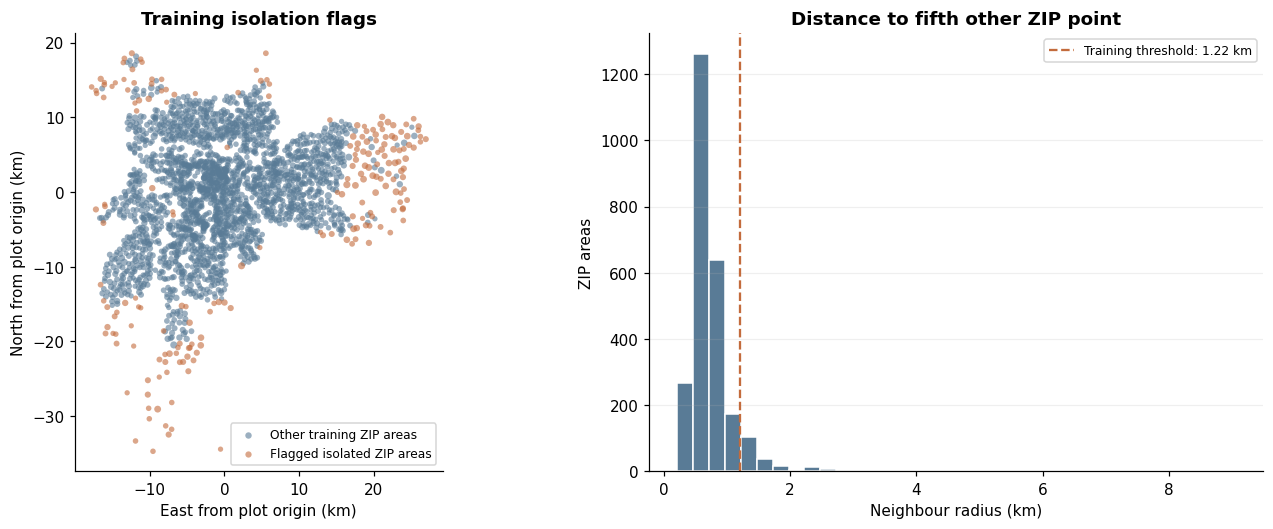

The tables and map identify the points used in the sensitivity check. **No flagged order has been removed from the main demand tables.**

In [ ]:
def isolation_diagnostics(demand, threshold=None):
    if len(demand) <= ISOLATION_NEIGHBORS:
        raise ValueError('Not enough ZIP points for the isolation diagnostic.')
    xy = projected_km(demand)
    # Query with the fitted data explicitly: self is one of the six neighbours.
    neighbours = NearestNeighbors(n_neighbors=ISOLATION_NEIGHBORS + 1)
    neighbours.fit(xy)
    distances, _ = neighbours.kneighbors(xy)
    radius = distances[:, ISOLATION_NEIGHBORS]
    if threshold is None:
        q1, q3 = np.quantile(radius, [0.25, 0.75])
        threshold = float(q3 + ISOLATION_IQR_MULTIPLIER * (q3 - q1))
    result = demand.copy()
    result['neighbour_radius_km'] = radius
    result['flagged_isolated'] = radius > threshold
    result['threshold_km'] = threshold
    return result, threshold

training_isolation, isolation_threshold = isolation_diagnostics(train_demand)
development_isolation, _ = isolation_diagnostics(development_demand, isolation_threshold)
reduced_training_demand = train_demand.loc[~training_isolation['flagged_isolated']].reset_index(drop=True)
reduced_development_demand = development_demand.loc[~development_isolation['flagged_isolated']].reset_index(drop=True)
isolation_summary = pd.DataFrame([
    {'Period': name, 'ZIP areas': len(flags), 'Orders': int(flags['orders'].sum()),
     'Flagged ZIP areas': int(flags['flagged_isolated'].sum()),
     'Flagged orders': int(flags.loc[flags['flagged_isolated'], 'orders'].sum()),
     'Flagged order share (%)': 100 * flags.loc[flags['flagged_isolated'], 'orders'].sum() / flags['orders'].sum(),
     'Threshold (km)': isolation_threshold}
    for name, flags in [('Training', training_isolation), ('Development', development_isolation)]
])
show_table(isolation_summary, 3)
show_table(training_isolation.loc[training_isolation['flagged_isolated'],
                                  ['zip_prefix', 'orders', 'neighbour_radius_km']]
           .sort_values('neighbour_radius_km', ascending=False).head(10), 3)
assert training_isolation['orders'].sum() == len(train_orders)
assert development_isolation['orders'].sum() == len(development_orders)
assert len(reduced_training_demand) >= max(CANDIDATE_COUNTS)
assert len(reduced_development_demand) >= max(CANDIDATE_COUNTS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
training_origin = training_xy.mean(axis=0)
flagged = training_isolation['flagged_isolated'].to_numpy()
for mask, label, color in [(~flagged, 'Other training ZIP areas', COLORS['K-Means']),
                            (flagged, 'Flagged isolated ZIP areas', COLORS['p-median'])]:
    axes[0].scatter(*(training_xy[mask] - training_origin).T,
                    s=9 + 3 * np.sqrt(training_weights[mask]), color=color,
                    alpha=0.60, linewidths=0, label=label)
axes[0].set(title='Training isolation flags', xlabel='East from plot origin (km)',
            ylabel='North from plot origin (km)')
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(fontsize=8)
axes[1].hist(training_isolation['neighbour_radius_km'], bins=35,
             color=COLORS['K-Means'], edgecolor='white')
axes[1].axvline(isolation_threshold, color=COLORS['p-median'], linestyle='--',
                label=f'Training threshold: {isolation_threshold:.2f} km')
axes[1].set(title='Distance to fifth other ZIP point', xlabel='Neighbour radius (km)', ylabel='ZIP areas')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.2)
finish_figure(fig, '10_isolation_diagnostics.png')
display(Markdown('The tables and map identify the points used in the sensitivity check. '
                 '**No flagged order has been removed from the main demand tables.**'))

## 7. Facility-location model

For demand area $i$ and candidate site $j$, let $w_i$ be the order count and $d_{ij}$ the distance in kilometres. Site-opening variable $y_j$ is binary. Assignment variable $x_{ij}$ allocates each area to an open site:

$$\min \sum_i\sum_j w_i d_{ij}x_{ij}$$

subject to

$$\sum_j x_{ij}=1\quad\forall i,\qquad x_{ij}\leq y_j\quad\forall i,j,$$

$$\sum_j y_j=p,\qquad y_j\in\{0,1\},\qquad 0\leq x_{ij}\leq1.$$

The lockers are **identical, coordinated and non-competing** in this model. There is no site-specific attractiveness, price or competing provider. Customers are assigned to their nearest open locker; the model does not predict adoption or market share.

There are no capacities, so continuous assignment variables are sufficient: once the sites are fixed, assigning each area entirely to its closest open site achieves the minimum. The reported assignments use that nearest-site rule. Only the site-opening decisions need integrality, which makes the model smaller for a city-wide study.

The solver minimizes the equivalent mean-distance objective by dividing weights by total demand. The requested relative optimality gap is 0.1%, with a 90-second limit per solve. Status, runtime and achieved gap are recorded; a time-limited feasible solution is not labelled as proven optimal. Optimality is always relative to the specified candidate pool.

In [ ]:
def solve_pmedian(distances, weights, count):
    distances = np.asarray(distances, dtype=float)
    weights = np.asarray(weights, dtype=float)
    n_areas, n_sites = distances.shape
    if not 1 <= count <= n_sites:
        raise ValueError('Locker count must be between one and the number of sites.')
    if len(weights) != n_areas or np.any(weights < 0) or weights.sum() <= 0:
        raise ValueError('Demand weights must be nonnegative and sum to a positive value.')
    if not np.isfinite(distances).all() or np.any(distances < 0):
        raise ValueError('Distances must be finite and nonnegative.')

    n_assignments = n_areas * n_sites
    assignment_columns = np.arange(n_assignments)
    assignment_rows = np.repeat(np.arange(n_areas), n_sites)
    opening_row = np.full(n_sites, n_areas)
    link_rows = n_areas + 1 + assignment_columns
    opening_columns = n_assignments + np.arange(n_sites)
    linked_opening_columns = n_assignments + np.tile(np.arange(n_sites), n_areas)

    rows = np.concatenate([assignment_rows, opening_row, link_rows, link_rows])
    columns = np.concatenate([assignment_columns, opening_columns,
                              assignment_columns, linked_opening_columns])
    values = np.concatenate([np.ones(n_assignments), np.ones(n_sites),
                             np.ones(n_assignments), -np.ones(n_assignments)])
    n_constraints = n_areas + 1 + n_assignments
    matrix = coo_matrix((values, (rows, columns)),
                        shape=(n_constraints, n_assignments + n_sites)).tocsc()
    lower = np.concatenate([np.ones(n_areas), [count], np.full(n_assignments, -np.inf)])
    upper = np.concatenate([np.ones(n_areas), [count], np.zeros(n_assignments)])
    objective = np.concatenate([(distances * (weights / weights.sum())[:, None]).ravel(),
                                np.zeros(n_sites)])
    integrality = np.concatenate([np.zeros(n_assignments), np.ones(n_sites)])

    started = perf_counter()
    result = milp(
        c=objective, integrality=integrality,
        bounds=Bounds(np.zeros(n_assignments + n_sites), np.ones(n_assignments + n_sites)),
        constraints=LinearConstraint(matrix, lower, upper),
        options={'time_limit': SOLVER_SECONDS, 'mip_rel_gap': RELATIVE_GAP},
    )
    elapsed = perf_counter() - started
    if result.x is None or result.status not in [0, 1]:
        raise RuntimeError(f'No usable solution: {result.message}')
    assignments = result.x[:n_assignments].reshape(n_areas, n_sites)
    opened = result.x[n_assignments:]
    selected = np.flatnonzero(opened > 0.5).tolist()
    assert len(selected) == count
    assert np.allclose(opened, np.round(opened), atol=1e-5)
    assert np.allclose(assignments.sum(axis=1), 1, atol=1e-5)
    assert np.all(assignments >= -1e-5)
    assert np.all(assignments <= opened[None, :] + 1e-5)
    nearest_objective = np.average(distances[:, selected].min(axis=1), weights=weights)
    assert np.isclose(nearest_objective, result.fun, atol=1e-5)

    information = {
        'Solver status': 'Optimal within tolerance' if result.status == 0 else 'Feasible; time/iteration limit',
        'Gap (%)': 100 * float(result.mip_gap), 'Runtime (s)': elapsed,
        'Mean objective (km)': nearest_objective,
    }
    return selected, information

# A tiny known problem checks formulation and assignment reconstruction.
check_distances = np.array([[0, 4, 8], [2, 2, 6], [8, 4, 0]], dtype=float)
check_selected, _ = solve_pmedian(check_distances, np.array([2, 1, 2]), 2)
assert set(check_selected) == {0, 2}
assert np.isclose(haversine_km([[0, 0]], [[0, 1]])[0, 0], 111.195, atol=0.01)
print('Distance and formulation checks passed.')

Distance and formulation checks passed.


## 8. Choose the candidate count using validation demand

Candidate counts of 15, 20 and 30 are compared using five lockers. Candidate sites and optimization weights come only from training orders. The setting with the lowest validation mean distance is retained; an exact tie is resolved in favour of fewer candidates.

This is a small sensitivity experiment, not a claim that the chosen count is universally best. The test period is not consulted during this selection.

In [ ]:
candidate_results = []
for count in CANDIDATE_COUNTS:
    sites, _ = make_candidates(train_demand, count)
    selected, solver_info = solve_pmedian(distance_matrix(train_demand, sites), train_demand['orders'], LOCKER_COUNT)
    validation_distance = distance_matrix(validation_demand, sites)[:, selected].min(axis=1)
    candidate_results.append({
        'Candidate sites': count,
        'Training mean (km)': solver_info['Mean objective (km)'],
        'Validation mean (km)': np.average(validation_distance, weights=validation_demand['orders']),
        **{key: solver_info[key] for key in ['Solver status', 'Gap (%)', 'Runtime (s)']},
    })
    print(f'Finished {count} candidates: {solver_info["Solver status"]}')

candidate_comparison = pd.DataFrame(candidate_results)
show_table(candidate_comparison, 3)
chosen_candidate_count = int(candidate_comparison.sort_values(
    ['Validation mean (km)', 'Candidate sites']).iloc[0]['Candidate sites'])
display(Markdown(f'**Selected candidate count: {chosen_candidate_count}.** The final candidate pool is now refitted using training and validation orders together.'))

Finished 15 candidates: Optimal within tolerance
Finished 20 candidates: Optimal within tolerance
Finished 30 candidates: Optimal within tolerance


Candidate sites,Training mean (km),Validation mean (km),Solver status,Gap (%),Runtime (s)
15,5.400,5.385,Optimal within tolerance,0.000,16.230
20,5.330,5.141,Optimal within tolerance,0.000,9.138
30,5.234,5.138,Optimal within tolerance,0.005,30.333


**Selected candidate count: 30.** The final candidate pool is now refitted using training and validation orders together.

## 9. Final candidate pool and placement

The final candidate pool uses the combined development period. The cluster plot shows how weighted K-Means groups demand; crosses mark the representative ZIP coordinates chosen as candidates. Five lockers are then selected from this pool using either clustering or optimization.

Solver status,Gap (%),Runtime (s),Mean objective (km)
Optimal within tolerance,0.0000,21.0402,5.1897


zip_prefix,lat,lon,site_id
03647,-23.52455,-46.52770,S01
01306,-23.55357,-46.64932,S02
05641,-23.61806,-46.73710,S03
05025,-23.53378,-46.68882,S04
04434,-23.68378,-46.66651,S05
03286,-23.59082,-46.53499,S06
04222,-23.59702,-46.59044,S07
02078,-23.50172,-46.59505,S08
08257,-23.55357,-46.42863,S09
04315,-23.63569,-46.62856,S10


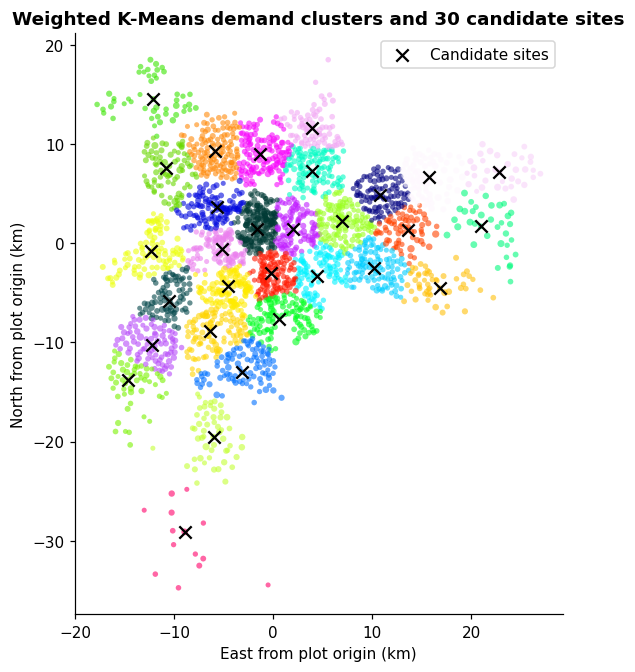

In [ ]:
candidate_sites, candidate_model = make_candidates(development_demand, chosen_candidate_count)
development_distances = distance_matrix(development_demand, candidate_sites)
test_distances = distance_matrix(test_demand, candidate_sites)
baseline_sites = kmeans_placement(development_demand, candidate_sites, LOCKER_COUNT)
optimized_sites, final_solver_info = solve_pmedian(
    development_distances, development_demand['orders'], LOCKER_COUNT
)
show_table(pd.DataFrame([final_solver_info]), 4)
show_table(candidate_sites, 5)

candidate_xy = projected_km(candidate_sites) - plot_origin
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.scatter(*(development_xy - plot_origin).T,
           s=8 + 3 * np.sqrt(development_demand['orders']), c=candidate_model.labels_,
           cmap='gist_ncar', alpha=0.60, linewidths=0)
ax.scatter(*candidate_xy.T, color='black', marker='x', s=65, linewidths=1.5, label='Candidate sites')
ax.set(title=f'Weighted K-Means demand clusters and {chosen_candidate_count} candidate sites',
       xlabel='East from plot origin (km)', ylabel='North from plot origin (km)')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='upper right')
finish_figure(fig, '04_clusters_and_candidates.png')

## 10. Evaluate on later orders

Every eligible test ZIP prefix is assigned to its closest selected locker. All statistics are weighted by the number of test orders in that prefix. The 1 km and 2 km coverage thresholds are illustrative service radii, not measured customer preferences.

For context, 200 random five-site placements are evaluated using the same candidate pool. Their average is a benchmark; no random run is selected using test performance. A held-out improvement is not guaranteed, even though the optimization directly targets development-period distance.

In [ ]:
def weighted_quantile(values, weights, quantile):
    order = np.argsort(values)
    sorted_values = np.asarray(values)[order]
    sorted_weights = np.asarray(weights)[order]
    position = np.searchsorted(np.cumsum(sorted_weights), quantile * sorted_weights.sum(), side='left')
    return float(sorted_values[min(position, len(sorted_values) - 1)])

def service_metrics(distances, weights, selected):
    nearest = distances[:, selected].min(axis=1)
    weights = np.asarray(weights, dtype=float)
    return {
        'Mean distance (km)': np.average(nearest, weights=weights),
        'Median distance (km)': weighted_quantile(nearest, weights, 0.50),
        'P90 distance (km)': weighted_quantile(nearest, weights, 0.90),
        'Within 1 km (%)': 100 * np.average(nearest <= 1, weights=weights),
        'Within 2 km (%)': 100 * np.average(nearest <= 2, weights=weights),
    }

placements = {'K-Means': baseline_sites, 'p-median': optimized_sites}
result_rows = []
for name, selected in placements.items():
    result_rows.append({
        'Method': name,
        'Development mean (km)': np.average(development_distances[:, selected].min(axis=1),
                                            weights=development_demand['orders']),
        **service_metrics(test_distances, test_demand['orders'], selected),
    })
comparison = pd.DataFrame(result_rows)
show_table(comparison, 3)

random_generator = np.random.default_rng(SEED)
random_results = []
for run in range(RANDOM_RUNS):
    selected = random_generator.choice(len(candidate_sites), size=LOCKER_COUNT, replace=False).tolist()
    random_results.append({'Run': run + 1, **service_metrics(test_distances, test_demand['orders'], selected)})
random_comparison = pd.DataFrame(random_results)
random_mean = random_comparison['Mean distance (km)'].mean()
show_table(pd.DataFrame([{
    'Random placements': RANDOM_RUNS, 'Mean of run means (km)': random_mean,
    '5th percentile of run means (km)': random_comparison['Mean distance (km)'].quantile(0.05),
    '95th percentile of run means (km)': random_comparison['Mean distance (km)'].quantile(0.95),
}]), 3)

baseline_test_mean = float(comparison.loc[comparison['Method'].eq('K-Means'), 'Mean distance (km)'].iloc[0])
optimized_test_mean = float(comparison.loc[comparison['Method'].eq('p-median'), 'Mean distance (km)'].iloc[0])
distance_change_pct = 100 * (baseline_test_mean - optimized_test_mean) / baseline_test_mean
verb = 'lower' if distance_change_pct >= 0 else 'higher'
same_site_set = set(baseline_sites) == set(optimized_sites)
if same_site_set:
    outcome_text = (
        f'Both methods choose the **same five candidate sites** and achieve a test mean distance of '
        f'**{optimized_test_mean:.3f} km** across **{len(test_orders):,} later orders**. '
        'The improvement over the clustering baseline is **0%**. For this scenario, optimization confirms '
        'the strong baseline rather than producing a different placement.'
    )
else:
    outcome_text = (
        f'On the later **{len(test_orders):,} orders**, optimized placement has a mean distance of '
        f'**{optimized_test_mean:.3f} km**, versus **{baseline_test_mean:.3f} km** for the clustering baseline '
        f'(**{abs(distance_change_pct):.2f}% {verb}**).'
    )
display(Markdown(outcome_text + ' These are simulated service distances, not measured delivery-cost savings.'))

Method,Development mean (km),Mean distance (km),Median distance (km),P90 distance (km),Within 1 km (%),Within 2 km (%)
K-Means,5.190,5.039,4.462,8.812,3.351,11.170
p-median,5.190,5.039,4.462,8.812,3.351,11.170


Random placements,Mean of run means (km),5th percentile of run means (km),95th percentile of run means (km)
200,6.969,5.765,8.985


Both methods choose the **same five candidate sites** and achieve a test mean distance of **5.039 km** across **3,044 later orders**. The improvement over the clustering baseline is **0%**. For this scenario, optimization confirms the strong baseline rather than producing a different placement. These are simulated service distances, not measured delivery-cost savings.

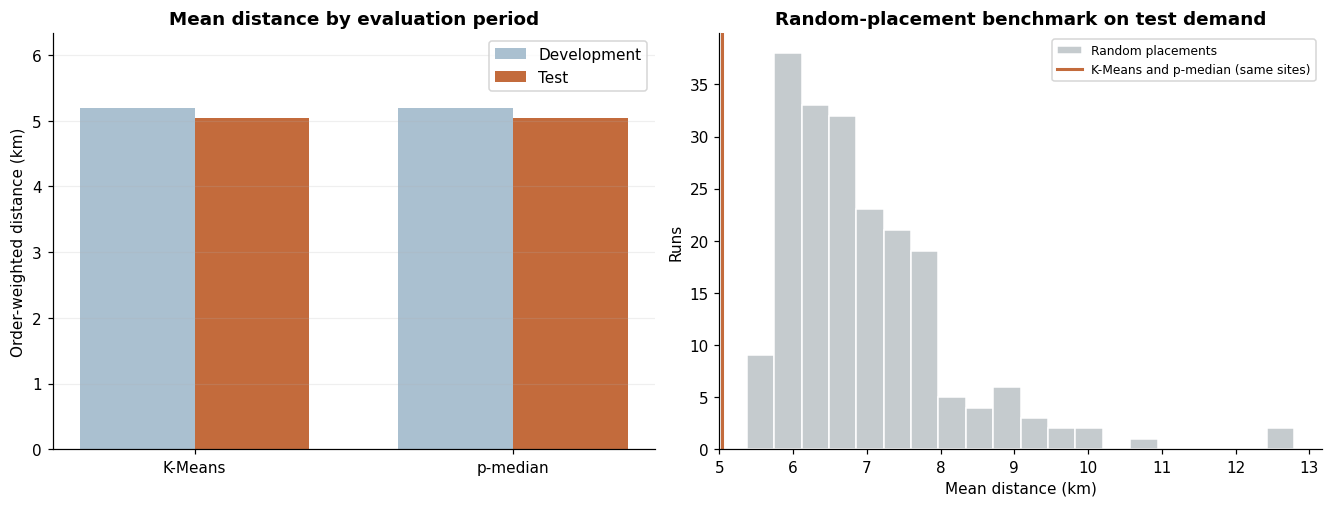

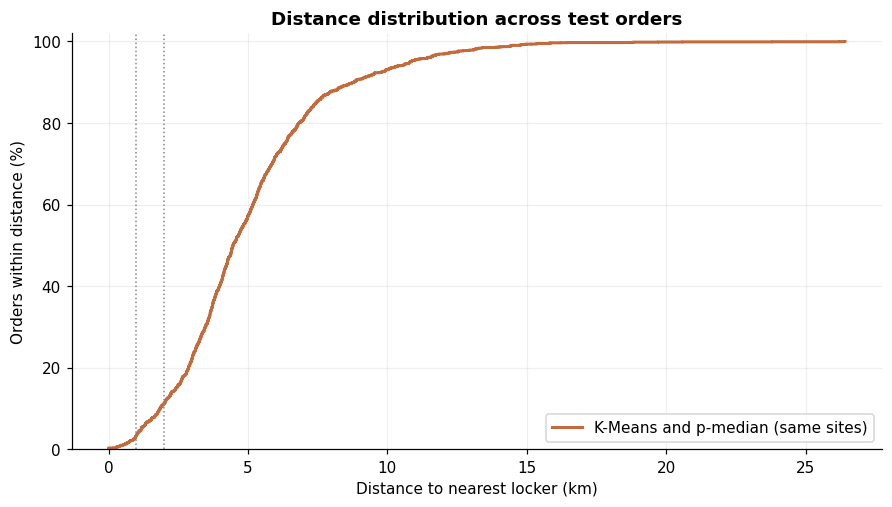

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
x = np.arange(len(comparison))
axes[0].bar(x - 0.18, comparison['Development mean (km)'], 0.36, label='Development', color='#aac0d0')
axes[0].bar(x + 0.18, comparison['Mean distance (km)'], 0.36, label='Test', color=COLORS['p-median'])
axes[0].set_xticks(x, comparison['Method'])
axes[0].set(title='Mean distance by evaluation period', ylabel='Order-weighted distance (km)',
            ylim=(0, 1.22 * comparison[['Development mean (km)', 'Mean distance (km)']].to_numpy().max()))
axes[0].legend()
axes[0].grid(axis='y', alpha=0.2)

axes[1].hist(random_comparison['Mean distance (km)'], bins=20, color='#c5cbce', edgecolor='white', label='Random placements')
if same_site_set:
    axes[1].axvline(optimized_test_mean, color=COLORS['p-median'], linewidth=2,
                    label='K-Means and p-median (same sites)')
else:
    axes[1].axvline(baseline_test_mean, color=COLORS['K-Means'], linewidth=2, label='K-Means')
    axes[1].axvline(optimized_test_mean, color=COLORS['p-median'], linewidth=2, label='p-median')
axes[1].set(title='Random-placement benchmark on test demand', xlabel='Mean distance (km)', ylabel='Runs')
axes[1].legend(fontsize=8)
finish_figure(fig, '05_method_comparison.png')

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
curve_placements = {'K-Means and p-median (same sites)': optimized_sites} if same_site_set else placements
for name, selected in curve_placements.items():
    nearest = test_distances[:, selected].min(axis=1)
    order = np.argsort(nearest)
    cumulative = np.cumsum(test_demand['orders'].to_numpy()[order]) / test_demand['orders'].sum()
    ax.step(nearest[order], 100 * cumulative, where='post', color=COLORS['p-median'] if same_site_set else COLORS[name], label=name, linewidth=2)
ax.axvline(1, color='#888888', linestyle=':', linewidth=1)
ax.axvline(2, color='#888888', linestyle=':', linewidth=1)
ax.set(title='Distance distribution across test orders', xlabel='Distance to nearest locker (km)',
       ylabel='Orders within distance (%)', ylim=(0, 102))
ax.legend()
ax.grid(alpha=0.2)
finish_figure(fig, '06_test_distance_distribution.png')

## 11. Assignments and selected-site demand

The following plots compare the service areas of the two placements. Each point is a ZIP-prefix representative location, coloured by the nearest selected locker. Marker size reflects development demand. The table reports historical orders assigned to each optimized site; it does not measure simultaneous locker occupancy or required locker capacity.

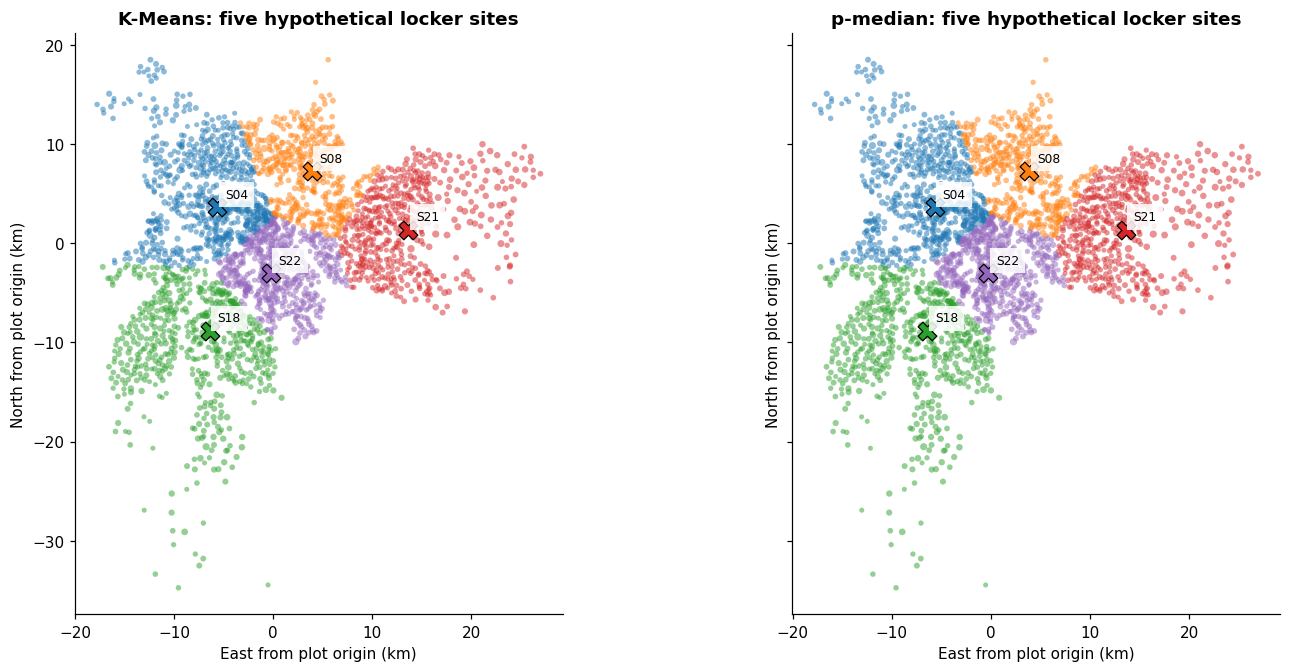

Site,ZIP prefix,Latitude,Longitude,Development orders,Test orders,Test share (%),Test mean distance (km)
S04,05025,-23.534,-46.689,2738,718,23.587,4.977
S08,02078,-23.502,-46.595,1547,402,13.206,4.114
S18,04739,-23.646,-46.698,2740,670,22.011,6.236
S21,03581,-23.556,-46.500,2304,550,18.068,6.169
S22,04035,-23.594,-46.637,2670,704,23.127,3.610


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True, constrained_layout=True)
palette = plt.get_cmap('tab10')
# A shared physical site uses the same colour in both placement panels.
site_colors = {site: palette(number) for number, site in
               enumerate(sorted(set(baseline_sites + optimized_sites)))}
for ax, (name, selected) in zip(axes, placements.items()):
    assigned_local = development_distances[:, selected].argmin(axis=1)
    for number, site_index in enumerate(selected):
        mask = assigned_local == number
        ax.scatter(*(development_xy[mask] - plot_origin).T,
                   s=8 + 3 * np.sqrt(development_demand.loc[mask, 'orders']),
                   color=site_colors[site_index], alpha=0.5, linewidths=0)
        ax.scatter(*candidate_xy[site_index], marker='X', color=site_colors[site_index],
                   s=150, edgecolor='black', linewidth=0.8, zorder=5)
        ax.annotate(candidate_sites.loc[site_index, 'site_id'], candidate_xy[site_index],
                    xytext=(5, 6), textcoords='offset points', fontsize=8,
                    bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none'}, zorder=6)
    ax.set(title=f'{name}: five hypothetical locker sites', xlabel='East from plot origin (km)',
           ylabel='North from plot origin (km)')
    ax.set_aspect('equal', adjustable='box')
finish_figure(fig, '07_placement_assignments.png')

def assignment_table(demand, distances, selected):
    local_site = distances[:, selected].argmin(axis=1)
    result = demand.copy()
    result['site_id'] = candidate_sites.iloc[np.asarray(selected)[local_site]]['site_id'].to_numpy()
    result['distance_km'] = distances[np.arange(len(demand)), np.asarray(selected)[local_site]]
    return result

development_assignments = assignment_table(development_demand, development_distances, optimized_sites)
test_assignments = assignment_table(test_demand, test_distances, optimized_sites)
selected_site_rows = []
for site_index in optimized_sites:
    site = candidate_sites.iloc[site_index]
    dev = development_assignments.loc[development_assignments['site_id'].eq(site['site_id'])]
    later = test_assignments.loc[test_assignments['site_id'].eq(site['site_id'])]
    selected_site_rows.append({
        'Site': site['site_id'], 'ZIP prefix': site['zip_prefix'],
        'Latitude': site['lat'], 'Longitude': site['lon'],
        'Development orders': int(dev['orders'].sum()), 'Test orders': int(later['orders'].sum()),
        'Test share (%)': 100 * later['orders'].sum() / len(test_orders),
        'Test mean distance (km)': np.average(later['distance_km'], weights=later['orders']) if len(later) else np.nan,
    })
selected_site_summary = pd.DataFrame(selected_site_rows)
show_table(selected_site_summary, 3)
assert selected_site_summary['Test orders'].sum() == len(test_orders)
assert selected_site_summary['Development orders'].sum() == len(development_orders)

## 12. Locker-count sensitivity

The candidate pool is held fixed while the number of lockers varies across 3, 5, 7 and 10. Both the clustering baseline and p-median are compared at each count. These scenarios were specified before the test comparison. Five remains the main scenario; the test curve is a description of those scenarios, not a method for choosing a deployment budget.

With exact optimization, adding lockers cannot increase the best development objective. The test curve need not be monotone because later demand can be distributed differently. Small deviations in development results may also arise from a nonzero solver gap. Installation costs and capacities are outside this model.

Finished 3 lockers: Optimal within tolerance
Finished 5 lockers: Optimal within tolerance
Finished 7 lockers: Optimal within tolerance
Finished 10 lockers: Optimal within tolerance


Lockers,Development mean (km),p-median test mean (km),K-Means test mean (km),Test reduction vs K-Means (%),Within 2 km (%)
3,6.429,6.301,6.301,0.000,9.330
5,5.190,5.039,5.039,0.000,11.170
7,4.429,4.317,4.638,6.938,15.375
10,3.669,3.634,3.730,2.581,22.503


Lockers,Solver status,Gap (%),Runtime (s)
3,Optimal within tolerance,0.000,24.333
5,Optimal within tolerance,0.000,21.040
7,Optimal within tolerance,0.000,19.311
10,Optimal within tolerance,0.000,18.821


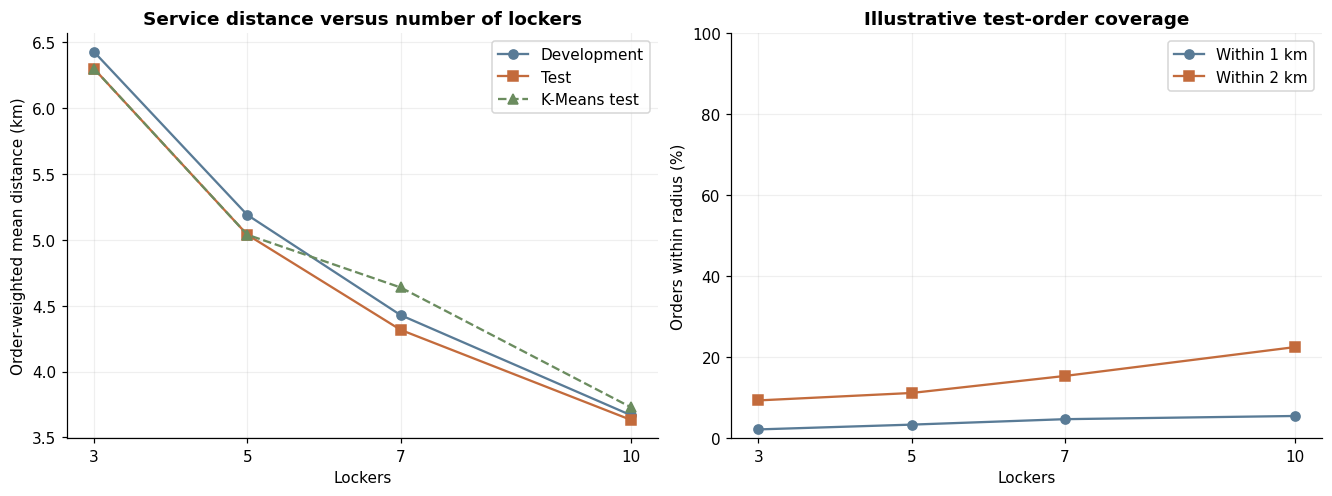

In [ ]:
sensitivity_rows = []
for count in LOCKER_COUNTS:
    if count == LOCKER_COUNT:
        selected, solver_info = optimized_sites, final_solver_info
    else:
        selected, solver_info = solve_pmedian(development_distances, development_demand['orders'], count)
    scenario_baseline = kmeans_placement(development_demand, candidate_sites, count)
    scenario_baseline_mean = np.average(test_distances[:, scenario_baseline].min(axis=1),
                                        weights=test_demand['orders'])
    scenario_optimized_mean = service_metrics(test_distances, test_demand['orders'], selected)['Mean distance (km)']
    sensitivity_rows.append({
        'Lockers': count, 'Development mean (km)': solver_info['Mean objective (km)'],
        **service_metrics(test_distances, test_demand['orders'], selected),
        'K-Means test mean (km)': scenario_baseline_mean,
        'Test reduction vs K-Means (%)': 100 * (scenario_baseline_mean - scenario_optimized_mean) / scenario_baseline_mean,
        **{key: solver_info[key] for key in ['Solver status', 'Gap (%)', 'Runtime (s)']},
    })
    print(f'Finished {count} lockers: {solver_info["Solver status"]}')
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity['Test mean change from previous scenario (km)'] = sensitivity['Mean distance (km)'].shift(1) - sensitivity['Mean distance (km)']
show_table(sensitivity[[
    'Lockers', 'Development mean (km)', 'Mean distance (km)', 'K-Means test mean (km)',
    'Test reduction vs K-Means (%)', 'Within 2 km (%)'
]].rename(columns={'Mean distance (km)': 'p-median test mean (km)'}), 3)
show_table(sensitivity[['Lockers', 'Solver status', 'Gap (%)', 'Runtime (s)']], 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
axes[0].plot(sensitivity['Lockers'], sensitivity['Development mean (km)'], marker='o', label='Development', color=COLORS['K-Means'])
axes[0].plot(sensitivity['Lockers'], sensitivity['Mean distance (km)'], marker='s', label='Test', color=COLORS['p-median'])
axes[0].plot(sensitivity['Lockers'], sensitivity['K-Means test mean (km)'], marker='^', linestyle='--', label='K-Means test', color='#6b8c5f')
axes[0].set(title='Service distance versus number of lockers', xlabel='Lockers', ylabel='Order-weighted mean distance (km)')
axes[0].set_xticks(LOCKER_COUNTS)
axes[0].legend()
axes[0].grid(alpha=0.2)
axes[1].plot(sensitivity['Lockers'], sensitivity['Within 1 km (%)'], marker='o', label='Within 1 km', color=COLORS['K-Means'])
axes[1].plot(sensitivity['Lockers'], sensitivity['Within 2 km (%)'], marker='s', label='Within 2 km', color=COLORS['p-median'])
axes[1].set(title='Illustrative test-order coverage', xlabel='Lockers', ylabel='Orders within radius (%)', ylim=(0, 100))
axes[1].set_xticks(LOCKER_COUNTS)
axes[1].legend()
axes[1].grid(alpha=0.2)
finish_figure(fig, '08_locker_count_sensitivity.png')

## 12.1 Candidate-generation outlier sensitivity

This experiment answers a specific question: **does excluding isolated points from candidate generation change the network's service to all customers?** It does not remove those customers from the optimization objective.

The alternative uses the candidate count selected by the original validation comparison and the same five-locker budget. Its K-Means candidate model fits the unflagged ZIP points and snaps centres to those points. The p-median then uses the **complete** training or development demand. Each variant's clustering baseline is fitted to complete demand and snapped to the same candidate pool as its p-median model. This isolates the candidate-generation change.

The first table checks the alternative on validation orders. The later-period table describes both frozen procedures; its test outcome does not choose a replacement main pipeline. Tail distances, coverage and service to flagged development prefixes are reported so that an average improvement cannot hide a peripheral service loss.

Variant,Candidate-fit ZIP areas,p-median training orders,Validation orders,Validation mean (km),Solver status,Gap (%)
Full candidate generation,2540,9006,2993,5.138,Optimal within tolerance,0.005
Unflagged candidate generation,2340,9006,2993,5.091,Optimal within tolerance,0.000


Candidate generation,Method,Lockers,Test orders,Mean distance (km),Median distance (km),P90 distance (km),Within 1 km (%),Within 2 km (%)
Full,K-Means,5,3044,5.039,4.462,8.812,3.351,11.170
Full,p-median,5,3044,5.039,4.462,8.812,3.351,11.170
Unflagged,K-Means,5,3044,5.272,5.101,8.284,2.332,9.691
Unflagged,p-median,5,3044,5.064,4.738,8.314,3.285,13.830


Variant,Solver status,Gap (%),Runtime (s),Mean objective (km)
Unflagged candidates,Optimal within tolerance,0.0000,23.9872,5.1642


Candidate generation,Test demand group,Test orders,Mean distance (km),Median distance (km),P90 distance (km),Within 1 km (%),Within 2 km (%)
Full,Flagged development prefixes,309,9.422,9.220,13.894,0.000,0.000
Full,Remaining test demand,2735,4.544,4.262,7.309,3.729,12.431
Unflagged,Flagged development prefixes,309,9.427,9.512,13.786,0.000,0.000
Unflagged,Remaining test demand,2735,4.571,4.487,7.353,3.656,15.393


zip_prefix,lat,lon,site_id,Development orders,Test orders
03575,-23.557,-46.508,R03,2653,627
02435,-23.481,-46.642,R04,1758,472
05816,-23.667,-46.739,R20,2005,465
05438,-23.547,-46.690,R22,2737,709
04139,-23.606,-46.634,R27,2846,771


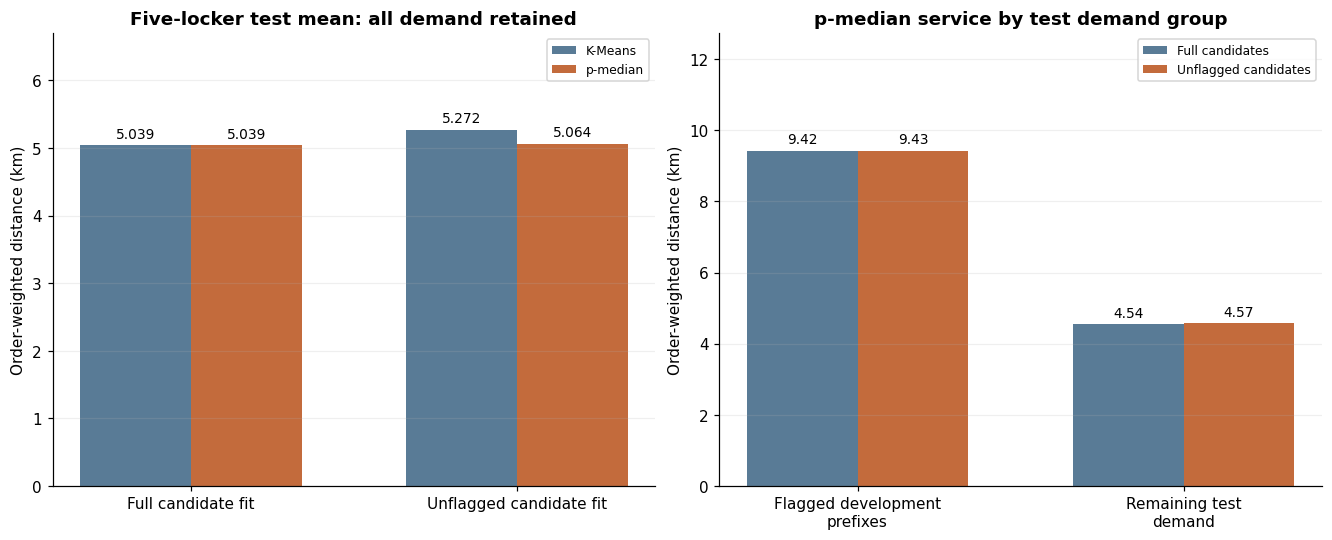

The alternative excludes **196 ZIP points** from candidate generation, while both optimizations retain **11,999 development orders** and both evaluations retain **3,044 test orders**. Its test mean is **5.064 km**, compared with **5.039 km** for the main network (**0.50% higher**). The two five-site networks share **0 exact representative coordinates**. **The full-data network remains the main result.**

In [ ]:
# Check the alternative on validation using training-only candidates and flags.
reduced_training_sites, _ = make_candidates(reduced_training_demand, chosen_candidate_count)
reduced_training_distances = distance_matrix(train_demand, reduced_training_sites)
reduced_training_selection, reduced_training_solver = solve_pmedian(
    reduced_training_distances, train_demand['orders'], LOCKER_COUNT
)
reduced_validation_distances = distance_matrix(validation_demand, reduced_training_sites)
original_validation_row = candidate_comparison.loc[
    candidate_comparison['Candidate sites'].eq(chosen_candidate_count)
].iloc[0]
outlier_validation = pd.DataFrame([
    {'Variant': 'Full candidate generation', 'Candidate-fit ZIP areas': len(train_demand),
     'p-median training orders': len(train_orders), 'Validation orders': len(validation_orders),
     'Validation mean (km)': original_validation_row['Validation mean (km)'],
     'Solver status': original_validation_row['Solver status'], 'Gap (%)': original_validation_row['Gap (%)']},
    {'Variant': 'Unflagged candidate generation', 'Candidate-fit ZIP areas': len(reduced_training_demand),
     'p-median training orders': len(train_orders), 'Validation orders': len(validation_orders),
     'Validation mean (km)': service_metrics(reduced_validation_distances,
                                              validation_demand['orders'], reduced_training_selection)['Mean distance (km)'],
     'Solver status': reduced_training_solver['Solver status'], 'Gap (%)': reduced_training_solver['Gap (%)']},
])
show_table(outlier_validation, 3)

# Refit candidate generation on development. Keep every development and test order.
reduced_candidate_sites, reduced_candidate_model = make_candidates(
    reduced_development_demand, chosen_candidate_count
)
reduced_candidate_sites['site_id'] = [f'R{index:02d}' for index in range(1, len(reduced_candidate_sites) + 1)]
reduced_development_distances = distance_matrix(development_demand, reduced_candidate_sites)
reduced_test_distances = distance_matrix(test_demand, reduced_candidate_sites)
reduced_baseline_sites = kmeans_placement(development_demand, reduced_candidate_sites, LOCKER_COUNT)
reduced_optimized_sites, reduced_solver_info = solve_pmedian(
    reduced_development_distances, development_demand['orders'], LOCKER_COUNT
)

sensitivity_variants = [
    ('Full', candidate_sites, development_distances, test_distances, baseline_sites, optimized_sites),
    ('Unflagged', reduced_candidate_sites, reduced_development_distances,
     reduced_test_distances, reduced_baseline_sites, reduced_optimized_sites),
]
outlier_rows = []
for variant, sites, dev_distances, later_distances, baseline, optimized in sensitivity_variants:
    assert dev_distances.shape[0] == len(development_demand)
    assert later_distances.shape[0] == len(test_demand)
    assert len(baseline) == len(optimized) == LOCKER_COUNT
    for method, selected in [('K-Means', baseline), ('p-median', optimized)]:
        outlier_rows.append({
            'Candidate generation': variant, 'Method': method,
            'Lockers': LOCKER_COUNT, 'Development orders': len(development_orders),
            'Test orders': len(test_orders), 'Candidate sites': len(sites),
            'Development mean (km)': np.average(dev_distances[:, selected].min(axis=1),
                                                weights=development_demand['orders']),
            **service_metrics(later_distances, test_demand['orders'], selected),
        })
outlier_comparison = pd.DataFrame(outlier_rows)
show_table(outlier_comparison[['Candidate generation', 'Method', 'Lockers', 'Test orders',
                               'Mean distance (km)', 'Median distance (km)', 'P90 distance (km)',
                               'Within 1 km (%)', 'Within 2 km (%)']], 3)
show_table(pd.DataFrame([{'Variant': 'Unflagged candidates', **reduced_solver_info}]), 4)

# Report service to flagged development prefixes without deriving new flags from test.
flagged_prefixes = set(development_isolation.loc[development_isolation['flagged_isolated'], 'zip_prefix'])
flagged_test_mask = test_demand['zip_prefix'].isin(flagged_prefixes).to_numpy()
group_rows = []
for variant, sites, _, later_distances, _, optimized in sensitivity_variants:
    for group, mask in [('Flagged development prefixes', flagged_test_mask),
                        ('Remaining test demand', ~flagged_test_mask)]:
        weights = test_demand.loc[mask, 'orders'].to_numpy()
        if not len(weights):
            continue
        group_rows.append({'Candidate generation': variant, 'Test demand group': group,
                           'Test orders': int(weights.sum()),
                           **service_metrics(later_distances[mask], weights, optimized)})
outlier_group_comparison = pd.DataFrame(group_rows)
show_table(outlier_group_comparison, 3)
for variant in ['Full', 'Unflagged']:
    assert outlier_group_comparison.loc[
        outlier_group_comparison['Candidate generation'].eq(variant), 'Test orders'
    ].sum() == len(test_orders)

# Export a complete assignment audit for the alternative network.
def assignments_for_sites(demand, distances, sites, selected):
    selected = np.asarray(selected)
    local = distances[:, selected].argmin(axis=1)
    result = demand.copy()
    result['site_id'] = sites.iloc[selected[local]]['site_id'].to_numpy()
    result['distance_km'] = distances[np.arange(len(demand)), selected[local]]
    return result

reduced_development_assignments = assignments_for_sites(
    development_demand, reduced_development_distances, reduced_candidate_sites, reduced_optimized_sites
)
reduced_test_assignments = assignments_for_sites(
    test_demand, reduced_test_distances, reduced_candidate_sites, reduced_optimized_sites
)
reduced_selected_site_summary = reduced_candidate_sites.iloc[reduced_optimized_sites].copy()
reduced_selected_site_summary['Development orders'] = reduced_selected_site_summary['site_id'].map(
    reduced_development_assignments.groupby('site_id')['orders'].sum()).fillna(0).astype(int)
reduced_selected_site_summary['Test orders'] = reduced_selected_site_summary['site_id'].map(
    reduced_test_assignments.groupby('site_id')['orders'].sum()).fillna(0).astype(int)
show_table(reduced_selected_site_summary, 3)
assert reduced_test_assignments['orders'].sum() == len(test_orders)
assert reduced_development_assignments['orders'].sum() == len(development_orders)
assert set(reduced_test_assignments['zip_prefix']) == set(test_demand['zip_prefix'])
assert set(reduced_development_assignments['zip_prefix']) == set(development_demand['zip_prefix'])
assert not set(reduced_candidate_sites['zip_prefix']) & flagged_prefixes

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for number, method in enumerate(['K-Means', 'p-median']):
    values = outlier_comparison.loc[outlier_comparison['Method'].eq(method), 'Mean distance (km)'].to_numpy()
    bars = axes[0].bar(np.arange(2) + (number - 0.5) * 0.34, values, width=0.34,
                       label=method, color=COLORS[method])
    axes[0].bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
axes[0].set_xticks([0, 1], ['Full candidate fit', 'Unflagged candidate fit'])
axes[0].set(title='Five-locker test mean: all demand retained', ylabel='Order-weighted distance (km)',
            ylim=(0, 1.27 * outlier_comparison['Mean distance (km)'].max()))
axes[0].legend(fontsize=8)
axes[0].grid(axis='y', alpha=0.2)

groups = outlier_group_comparison['Test demand group'].drop_duplicates().tolist()
for number, variant in enumerate(['Full', 'Unflagged']):
    subset = outlier_group_comparison.loc[outlier_group_comparison['Candidate generation'].eq(variant)].set_index('Test demand group')
    values = subset.loc[groups, 'Mean distance (km)'].to_numpy()
    bars = axes[1].bar(np.arange(len(groups)) + (number - 0.5) * 0.34, values, width=0.34,
                       label=f'{variant} candidates', color=['#597b96', '#c36b3c'][number])
    axes[1].bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
axes[1].set_xticks(np.arange(len(groups)),
                   ['Flagged development\nprefixes' if group.startswith('Flagged') else 'Remaining test\ndemand' for group in groups])
axes[1].set(title='p-median service by test demand group', ylabel='Order-weighted distance (km)',
            ylim=(0, 1.35 * outlier_group_comparison['Mean distance (km)'].max()))
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.2)
finish_figure(fig, '11_outlier_sensitivity.png')

full_mean = outlier_comparison.loc[outlier_comparison['Candidate generation'].eq('Full') &
                                  outlier_comparison['Method'].eq('p-median'), 'Mean distance (km)'].iloc[0]
reduced_mean = outlier_comparison.loc[outlier_comparison['Candidate generation'].eq('Unflagged') &
                                     outlier_comparison['Method'].eq('p-median'), 'Mean distance (km)'].iloc[0]
outlier_change_pct = 100 * (full_mean - reduced_mean) / full_mean
outlier_direction = 'lower' if outlier_change_pct >= 0 else 'higher'
full_coordinates = set(map(tuple, candidate_sites.iloc[optimized_sites][['lat', 'lon']].to_numpy()))
reduced_coordinates = set(map(tuple, reduced_candidate_sites.iloc[reduced_optimized_sites][['lat', 'lon']].to_numpy()))
common_site_count = len(full_coordinates & reduced_coordinates)
display(Markdown(
    f'The alternative excludes **{int(development_isolation["flagged_isolated"].sum())} ZIP points** '
    'from candidate generation, while both optimizations retain '
    f'**{len(development_orders):,} development orders** and both evaluations retain '
    f'**{len(test_orders):,} test orders**. Its test mean is **{reduced_mean:.3f} km**, '
    f'compared with **{full_mean:.3f} km** for the main network '
    f'(**{abs(outlier_change_pct):.2f}% {outlier_direction}**). '
    f'The two five-site networks share **{common_site_count} exact representative coordinates**. '
    '**The full-data network remains the main result.**'
))

## 13. Findings and limitations

The result should be interpreted as a demand-location study. It supports comparing hypothetical placements under one set of assumptions, rather than claiming actual operational savings.

In [ ]:
optimized_metrics = comparison.loc[comparison['Method'].eq('p-median')].iloc[0]
three_distance = sensitivity.loc[sensitivity['Lockers'].eq(3), 'Mean distance (km)'].iloc[0]
ten_distance = sensitivity.loc[sensitivity['Lockers'].eq(10), 'Mean distance (km)'].iloc[0]
display(Markdown(
    f'- The city-wide eligible cohort contains **{len(order_areas):,} delivered orders** across **{len(all_demand):,} ZIP prefixes**.\n'
    f'- Validation selected **{chosen_candidate_count} candidate sites**, and the main model opened **five** of them.\n'
    f'- On later orders, mean straight-line distance is **{optimized_test_mean:.3f} km** for p-median and '
    f'**{baseline_test_mean:.3f} km** for the clustering baseline. '
    + ('**The methods select the same five sites; there is no reduction over this baseline.**\n' if same_site_set
       else f'The optimized mean is **{abs(distance_change_pct):.2f}% {verb}**.\n')
    +
    f'- For the optimized five-site placement, **{optimized_metrics["Within 2 km (%)"]:.1f}%** of test orders are within 2 km; '
    f'the 90th-percentile distance is **{optimized_metrics["P90 distance (km)"]:.2f} km**.\n'
    f'- Across the specified scenarios, test mean distance changes from **{three_distance:.2f} km** with three lockers '
    f'to **{ten_distance:.2f} km** with ten.\n'
    f'- Final five-site solver status: **{final_solver_info["Solver status"]}**, '
    f'with a reported relative gap of **{final_solver_info["Gap (%)"]:.4f}%**.'
))

seven_locker_result = sensitivity.loc[sensitivity['Lockers'].eq(7)].iloc[0]
seven_change = seven_locker_result['Test reduction vs K-Means (%)']
seven_direction = 'lower' if seven_change >= 0 else 'higher'
display(Markdown(
    f'With **seven lockers**, p-median achieves a test mean distance of '
    f'**{seven_locker_result["Mean distance (km)"]:.3f} km**, compared with '
    f'**{seven_locker_result["K-Means test mean (km)"]:.3f} km** for K-Means '
    f'(**{abs(seven_change):.2f}% {seven_direction}**). The benefit therefore depends on the locker-count scenario; '
    + ('the five-locker comparison remains a tie.' if same_site_set else 'five lockers remains the main scenario.')
))

- The city-wide eligible cohort contains **15,043 delivered orders** across **2,824 ZIP prefixes**.
- Validation selected **30 candidate sites**, and the main model opened **five** of them.
- On later orders, mean straight-line distance is **5.039 km** for p-median and **5.039 km** for the clustering baseline. **The methods select the same five sites; there is no reduction over this baseline.**
- For the optimized five-site placement, **11.2%** of test orders are within 2 km; the 90th-percentile distance is **8.81 km**.
- Across the specified scenarios, test mean distance changes from **6.30 km** with three lockers to **3.63 km** with ten.
- Final five-site solver status: **Optimal within tolerance**, with a reported relative gap of **0.0000%**.

With **seven lockers**, p-median achieves a test mean distance of **4.317 km**, compared with **4.638 km** for K-Means (**6.94% lower**). The benefit therefore depends on the locker-count scenario; the five-locker comparison remains a tie.

The main limitations are:

- **Demand proxy:** historical orders measure activity on Olist, not the city's full parcel market. Locker adoption and willingness to travel are unknown.
- **Retrospective cohort:** the study uses orders eventually recorded as delivered and splits them by purchase date. It is not a production replay of everything known at each historical date. Filtering by final status can introduce selection effects.
- **Location precision:** all orders in a ZIP prefix share a representative coordinate. Some prefixes have considerable coordinate spread.
- **Distance:** straight-line kilometres do not account for streets, barriers, walking routes or accessibility.
- **Candidate feasibility:** a coordinate does not establish property availability, opening hours, security or permissions.
- **Operational scope:** installation costs, locker sizes, parcel dwell time and capacity constraints are not included. Assigned historical order counts are not occupancy forecasts.
- **Isolation rule:** nearest-neighbour spacing reflects the available ZIP points, not a verified boundary between valid customers and errors. Excluding flagged points is only a candidate-generation sensitivity, and can reduce service to peripheral demand.
- **Evaluation scope:** all eligible geocoded city orders are evaluated, but orders removed during filtering are excluded. One temporal split and one clustering seed do not establish stability across future periods.

A useful next extension would replace hypothetical candidates with verified pickup properties and road-network distances. Capacity can then be added once a planning period and parcel dwell-time assumptions are defined.